# AT2 - Previsão de churn com MLP

## 1. Contexto do problema e dicionário de dados

Dataset: [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (Kaggle).

São dados de clientes de uma empresa de telecom. O objetivo é prever se o cliente vai cancelar o serviço
(churn), assim a empresa consegue tentar manter esse cliente antes dele sair.

Problema de classificação binária: `Yes` (cancelou) ou `No` (não cancelou).

| Coluna | Tipo | Significado |
|---|---|---|
| tenure | int | meses como cliente |
| MonthlyCharges | float | valor da mensalidade |
| TotalCharges | float | valor total já pago |
| SeniorCitizen | int | 1 se for idoso, 0 se não |
| Contract | texto | tipo de contrato (Month-to-month, One year, Two year) |
| InternetService | texto | tipo de internet (DSL, Fiber optic, No) |
| PaymentMethod | texto | forma de pagamento |
| TechSupport | texto | tem suporte técnico (Yes, No, No internet service) |
| Churn | texto | alvo: se cancelou (Yes/No) |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Análise exploratória

In [2]:
df = pd.read_csv("../data/dataset.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


A coluna TotalCharges veio como texto e tem alguns valores em branco, então converti pra número.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Só 11 linhas ficaram nulas, então removi elas.

In [4]:
df = df.dropna()
print(df.shape)

(7032, 21)


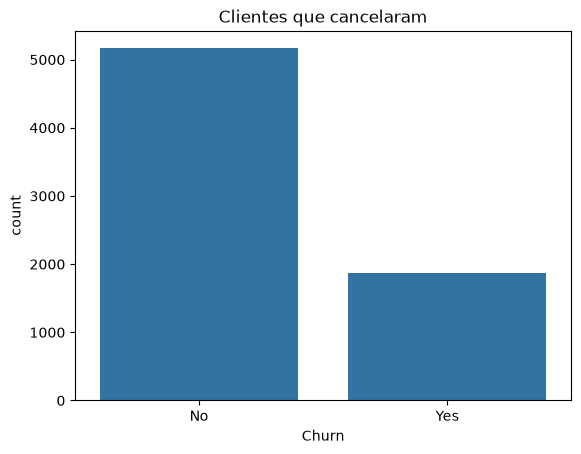

Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


In [5]:
sns.countplot(data=df, x="Churn")
plt.title("Clientes que cancelaram")
plt.show()

print(df["Churn"].value_counts(normalize=True))

A maioria dos clientes não cancelou (uns 73%), então os dados estão desbalanceados.

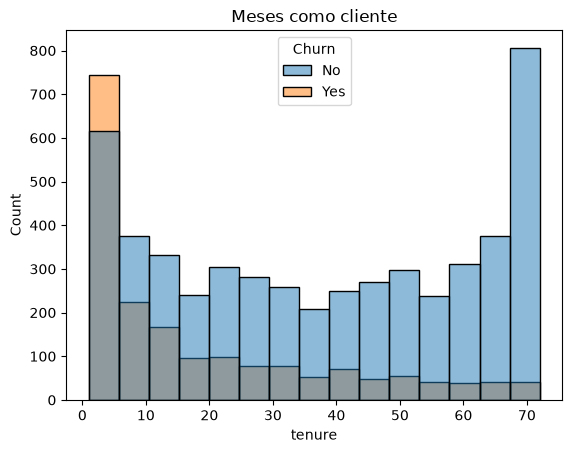

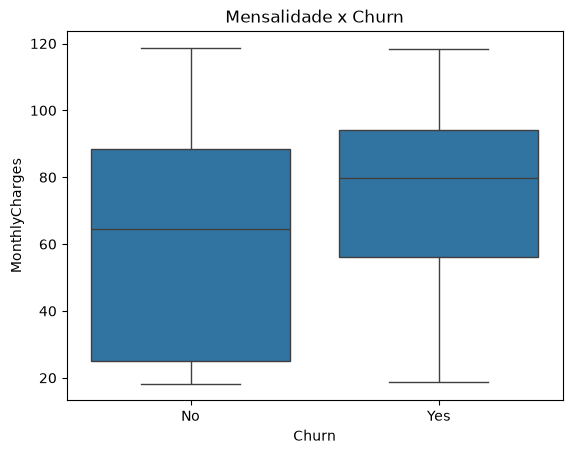

In [6]:
sns.histplot(data=df, x="tenure", hue="Churn")
plt.title("Meses como cliente")
plt.show()

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Mensalidade x Churn")
plt.show()

Quem cancela costuma ter pouco tempo de empresa e mensalidade mais alta.

## 3. Pipeline

In [7]:
colunas_num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
colunas_cat = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]

X = df[colunas_num + colunas_cat]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
preprocessamento = ColumnTransformer([
    ("num", StandardScaler(), colunas_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_cat),
])

modelo = Pipeline([
    ("preprocessamento", preprocessamento),
    ("mlp", MLPClassifier(hidden_layer_sizes=(64, 32), learning_rate_init=0.001,
                          max_iter=500, early_stopping=True, random_state=42)),
])

modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U3](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['tenure','MonthlyCharges','TotalCharges',...,'InternetService', 'PaymentMethod','TechSupport']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

## 4. Avaliação

In [9]:
y_pred = modelo.predict(X_test)
print("Acurácia:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Acurácia: 0.8009950248756219
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1033
         Yes       0.65      0.53      0.59       374

    accuracy                           0.80      1407
   macro avg       0.75      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



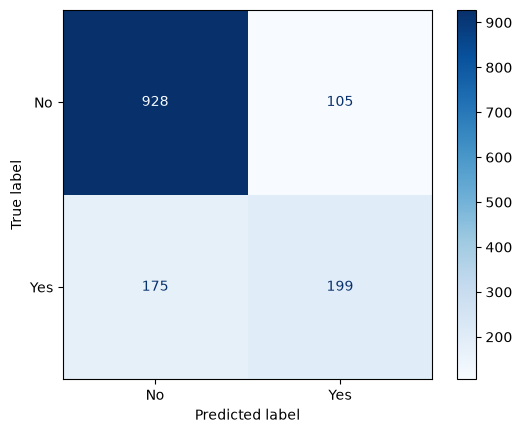

In [10]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.show()

A acurácia ficou perto de 80%. O modelo acerta bem quem não cancela, mas erra mais quem cancela
(falsos negativos), que é o erro mais ruim pra empresa porque o cliente sai sem ninguém perceber.

## 5. Exportação do modelo

In [11]:
joblib.dump(modelo, "../models/modelo_mlp.joblib")

['../models/modelo_mlp.joblib']